# Dulles freezing-day forecasts: preliminary results
**Question:** Can recent Dulles daily minimum temperatures and season improve a forecast used to flag potential pretreatment days?

**Quantity:** next calendar day's minimum airport air temperature, in °F, one daily value. This is a preliminary proxy for the proposal's overnight campus-pavement target. Daily records cannot isolate the overnight window or establish whether ice formed.

Forecast origin: afternoon of day $t-1$; target: daily minimum on $t$. Only temperatures dated $t-2$ or earlier enter the predictors, conservatively allowing a full completed day. Historical final NOAA records do not prove real-time release availability; that must be audited before deployment.

This notebook compares methods and three hypothetical cost scenarios. It does not select GMU's operational cost ratio or claim an actual salting policy. AI assistance: ChatGPT/Codex prepared the code and draft explanations; team members must review and be able to explain them.


In [1]:
from pathlib import Path
import hashlib
import calendar
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / 'data').is_dir(), 'Run from the repository root.'
FIG = ROOT / 'fig'
FIG.mkdir(exist_ok=True)
SEED = 600
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches='tight')
    plt.show()


## Data and provenance
NOAA GHCN-Daily station **USW00093738**, WASHINGTON DULLES INTL AP (38.9347, −77.4472; elevation 89.6 m), corresponding to KIAD. Source: https://www.ncei.noaa.gov/pub/data/ghcn/daily/all/USW00093738.dly . Format and quality flags: https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt .

Unit of observation: a station day, assembled from the monthly fixed-width records. TMIN is in tenths of °C; convert to °F. Reject missing values (−9999) and nonblank NOAA quality flags. Reindex to a complete calendar **before** creating lags, so a gap never becomes 'yesterday.' Retain measurement/source flags in the parsed table. No fabricated or interpolated temperatures.

Use complete calendar years 2000–2025, excluding partial 2026. GHCN aggregates station observations with source and quality processing; this notebook does not verify instrument history. Airport air and campus pavement differ systematically, and air freezing alone does not establish surface ice. These are target/proxy biases, not merely random measurement errors.


Calendar days: 9,497; usable TMIN: 9,497; missing/rejected: 0
Nonblank quality flags rejected: 0


,tmin_f
count,9497.00
mean,45.99
std,17.00
min,-3.82
25%,32.00
50%,46.04
75%,60.98
max,78.98


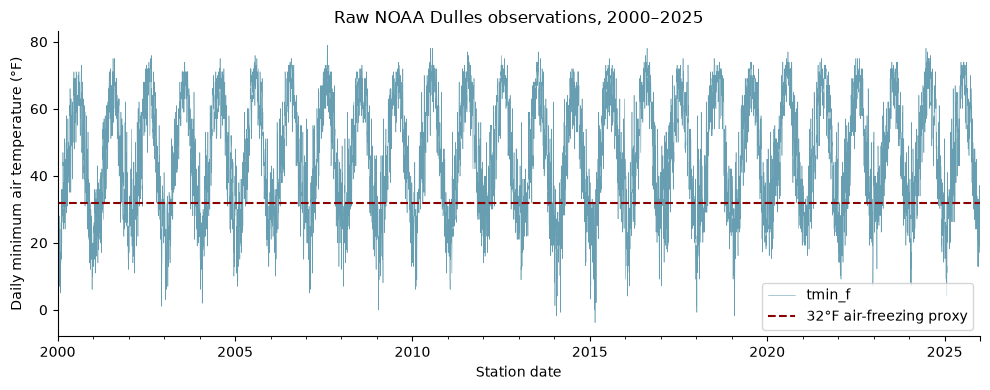

In [2]:
DATA = ROOT / 'data/USW00093738.dly'
EXPECTED_SHA256 = '5740ef38697685f37a90dd81b3b9dedd2b67e9fa7a4ed2164850f16aaba6ef84'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == EXPECTED_SHA256, 'Data hash differs: review source and document any revision.'
rows = []
for line in DATA.read_text().splitlines():
    if line[17:21] != 'TMIN':
        continue
    year, month = int(line[11:15]), int(line[15:17])
    if not 2000 <= year <= 2025:
        continue
    for day in range(1, calendar.monthrange(year, month)[1] + 1):
        start = 21 + 8 * (day - 1)
        value = int(line[start:start+5])
        quality = line[start+6:start+7].strip()
        rows.append({'date': pd.Timestamp(year, month, day),
                     'tmin_f': np.nan if value == -9999 or quality else value / 10 * 9 / 5 + 32,
                     'quality': quality, 'measurement': line[start+5:start+6],
                     'source': line[start+7:start+8]})
parsed = pd.DataFrame(rows).set_index('date').sort_index()
assert not parsed.index.duplicated().any()
daily = parsed.reindex(pd.date_range('2000-01-01', '2025-12-31', name='date'))
print(f'Calendar days: {len(daily):,}; usable TMIN: {daily.tmin_f.notna().sum():,}; missing/rejected: {daily.tmin_f.isna().sum():,}')
print('Nonblank quality flags rejected:', int(parsed.quality.ne('').sum()))
display(daily[['tmin_f']].describe().round(2))
ax = daily.tmin_f.plot(lw=.4, alpha=.65, color='#176b87')
ax.axhline(32, color='darkred', ls='--', label='32°F air-freezing proxy')
ax.set(ylabel='Daily minimum air temperature (°F)', xlabel='Station date', title='Raw NOAA Dulles observations, 2000–2025')
ax.legend()
save('raw_temperature.png')


## Split and predictors, fixed before scoring
Training: 2000–2018. Calibration: 2019–2021, used only to estimate each method's forecast-error distribution. Test: 2022–2025, never used for fitting, thresholds, features, or choosing the model. No random split, scaling, or hyperparameter search. Calendar features are known in advance. Lag 2 and lag 3 deliberately exclude the incomplete forecast-origin day's minimum.

Compared with a random split, this better represents forecasting a later period, but one cutoff cannot establish performance in every climate regime. Revisit using rolling-origin evaluation if results vary strongly by test year. The raw-data display above is descriptive, not used to select predictors.


In [3]:
df = daily[['tmin_f']].copy()
df['lag2'] = df.tmin_f.shift(2)
df['lag3'] = df.tmin_f.shift(3)
angle = 2 * np.pi * (df.index.day_of_year - 1) / 365.2425
df['sin_year'], df['cos_year'] = np.sin(angle), np.cos(angle)
features = ['lag2', 'lag3', 'sin_year', 'cos_year']
usable = df.dropna(subset=['tmin_f'] + features)
train = usable.loc[:'2018-12-31'].copy()
cal = usable.loc['2019-01-01':'2021-12-31'].copy()
test = usable.loc['2022-01-01':'2025-12-31'].copy()
assert train.index.max() < cal.index.min() < test.index.min()
split_table = pd.DataFrame([{'split': name, 'start': str(part.index.min().date()),
    'end': str(part.index.max().date()), 'days': len(part),
    'freezing_days': int((part.tmin_f <= 32).sum())}
    for name, part in [('train', train), ('calibration', cal), ('test', test)]])
display(split_table)
print('Rows excluded for target/predictor gaps:', len(df) - len(usable))


,split,start,end,days,freezing_days
0,train,2000-01-04,2018-12-31,6937,1921
1,calibration,2019-01-01,2021-12-31,1096,267
2,test,2022-01-01,2025-12-31,1461,342


Rows excluded for target/predictor gaps: 3


## Baseline and model
Baseline persistence: $\hat T_t=T_{t-2}$, the latest conservatively available completed-day minimum.

Regression: $T_t=\beta_0+\beta_1T_{t-2}+\beta_2T_{t-3}+\beta_3\sin(2\pi d_t/365.2425)+\beta_4\cos(2\pi d_t/365.2425)+\epsilon_t$.

The intercept is the offset in °F; lag coefficients (°F/°F) describe persistence conditional on the other lag and season. Sine/cosine coefficients describe annual seasonal variation in °F, not causal effects. Fit ordinary least squares on training rows only. Compared with a tree or neural network, this has less flexibility but is easier to explain and less prone to tuning against a small number of freeze events.

For uncertainty use the empirical calibration residual distribution, separately for each method: $T_t^*=\hat T_t+e_j^{cal}$. Its 5th and 95th percentiles form a nominal 90% prediction interval. No Gaussian assumption is needed. The least-trusted assumption is that residuals transfer across seasons and future years: cold fronts and changing weather may violate it. Intervals are empirical and have no guaranteed conditional coverage.


In [4]:
model = LinearRegression().fit(train[features], train.tmin_f)
display(pd.Series([model.intercept_, *model.coef_], index=['intercept'] + features, name='coefficient').round(4).to_frame())
pred_cal = {'Persistence': cal.lag2.to_numpy(), 'Regression': model.predict(cal[features])}
pred_test = {'Persistence': test.lag2.to_numpy(), 'Regression': model.predict(test[features])}
errors_cal = {name: cal.tmin_f.to_numpy() - pred for name, pred in pred_cal.items()}
prob = {}
intervals = {}
forecast_rows = []
actual = test.tmin_f.to_numpy()
freeze = actual <= 32
for name, pred in pred_test.items():
    errors = errors_cal[name]
    prob[name] = (pred[:, None] + errors[None, :] <= 32).mean(axis=1)
    lo, hi = np.quantile(errors, [.05, .95])
    intervals[name] = (pred + lo, pred + hi)
    forecast_rows.append({'method': name, 'MAE_F': np.abs(actual-pred).mean(),
        'RMSE_F': np.sqrt(np.mean((actual-pred)**2)), 'mean_error_F': (actual-pred).mean(),
        '90pct_interval_coverage': ((actual >= pred+lo) & (actual <= pred+hi)).mean(),
        'mean_interval_width_F': hi-lo, 'Brier_score': np.mean((prob[name]-freeze)**2)})
forecast_scores = pd.DataFrame(forecast_rows)
display(forecast_scores.round(4))
forecast_scores.to_csv(FIG / 'forecast_scores.csv', index=False)


,coefficient
intercept,31.9910
lag2,0.3192
lag3,-0.0205
sin_year,-4.6725
cos_year,-14.2655


,method,MAE_F,RMSE_F,mean_error_F,90pct_interval_coverage,mean_interval_width_F,Brier_score
0,Persistence,7.4003,9.5088,-0.0404,0.9103,31.8600,0.1108
1,Regression,6.1439,7.7027,0.8379,0.8946,24.5257,0.0927


## Decision and held-out loss
Let $z=1$ mean daily air minimum $\le32^\circ F$, and $a=1$ mean a hypothetical pretreatment flag. Use $L(a,z;r)=r\,1(a=0,z=1)+1(a=1,z=0)$. Correct actions have zero **regret** in this simplified table. One unit equals the penalty assigned to one unnecessary-treatment day; it is not a measured dollar cost. This omits treatment costs on freezing days, incomplete effectiveness, wetness and environmental effects.

Expected regret of treating is $1-p$; of standing down is $rp$. Flag when $p\ge1/(r+1)$. Report $r=2,5,10$ separately; no ratio is declared correct. Both methods get identical costs and test days. Include always/never-treatment reference policies to reveal whether forecasting adds value. Counts are station **days**, not verified icy nights or accidents.


,miss_penalty,method,threshold,flagged_days,missed_freezing_days,unnecessary_flag_days,total_penalty_units,penalty_per_100_days
0,2,Persistence,0.333,463,76,197,349,23.888
1,2,Regression,0.333,443,53,154,260,17.796
2,2,Always flag,0.333,1461,0,1119,1119,76.591
3,2,Never flag,0.333,0,342,0,684,46.817
4,5,Persistence,0.167,576,36,270,450,30.801
5,5,Regression,0.167,564,21,243,348,23.819
6,5,Always flag,0.167,1461,0,1119,1119,76.591
7,5,Never flag,0.167,0,342,0,1710,117.043
8,10,Persistence,0.091,677,15,350,500,34.223
9,10,Regression,0.091,619,12,289,409,27.995


method,Always flag,Never flag,Persistence,Regression,regression_saving_vs_persistence
miss_penalty,,,,,
2,1119,684,349,260,89
5,1119,1710,450,348,102
10,1119,3420,500,409,91


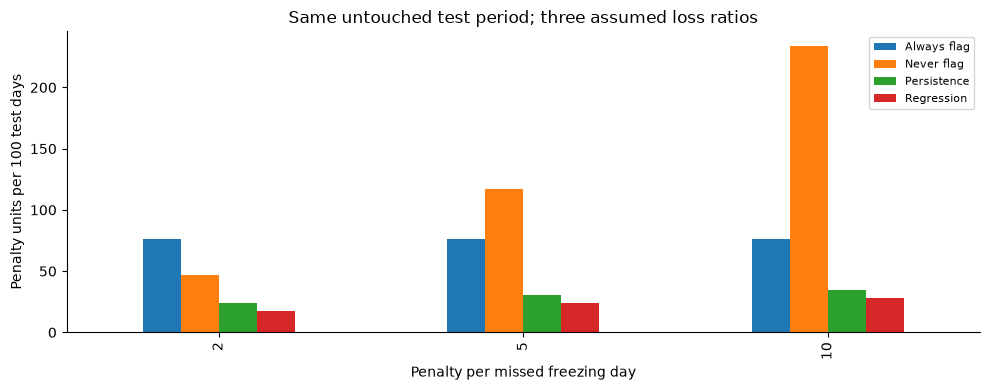

A perfect forecast would have zero regret under this simplified table. Thus each total above is an upper bound on the value of perfect information in that scenario, not an achievable saving or a dollar estimate. Regression savings versus persistence are descriptive held-out differences, not a guarantee.

In [5]:
decision_rows = []
for ratio in [2, 5, 10]:
    methods = {**{name: p >= 1/(ratio+1) for name, p in prob.items()},
               'Always flag': np.ones(len(test), dtype=bool),
               'Never flag': np.zeros(len(test), dtype=bool)}
    for name, action in methods.items():
        missed = int((~action & freeze).sum())
        unnecessary = int((action & ~freeze).sum())
        loss = ratio * missed + unnecessary
        decision_rows.append({'miss_penalty': ratio, 'method': name, 'threshold': 1/(ratio+1),
            'flagged_days': int(action.sum()), 'missed_freezing_days': missed,
            'unnecessary_flag_days': unnecessary, 'total_penalty_units': loss,
            'penalty_per_100_days': 100*loss/len(test)})
scores = pd.DataFrame(decision_rows)
display(scores.round(3))
scores.to_csv(FIG / 'decision_scores.csv', index=False)
comparison = scores.pivot(index='miss_penalty', columns='method', values='total_penalty_units')
comparison['regression_saving_vs_persistence'] = comparison.Persistence - comparison.Regression
display(comparison)
ax = scores.pivot(index='miss_penalty', columns='method', values='penalty_per_100_days').plot.bar()
ax.set(ylabel='Penalty units per 100 test days', xlabel='Penalty per missed freezing day', title='Same untouched test period; three assumed loss ratios')
ax.legend(fontsize=8)
save('decision_loss.png')
display(Markdown('A perfect forecast would have zero regret under this simplified table. Thus each total above is an upper bound on the value of perfect information in that scenario, not an achievable saving or a dollar estimate. Regression savings versus persistence are descriptive held-out differences, not a guarantee.'))


## Residuals, calibration, and stability
Inspect residual structure and freezing-probability calibration without refitting on the test set. Predictions in each bin should roughly match the observed fraction; sparse bins are unreliable. Annual errors test temporal stability, but these are all the same forecast horizon: they do not establish how error grows for longer forecasts.


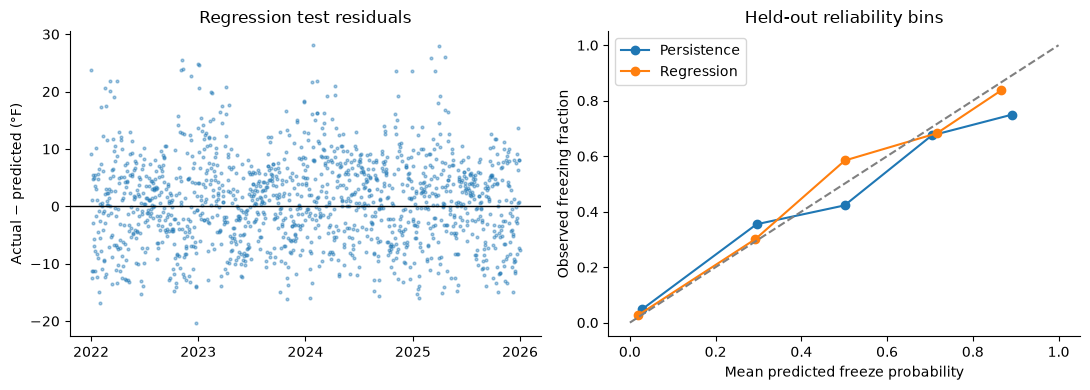

,bin,mean_probability,observed_fraction,days,method
0,"(-0.001, 0.2]",0.029,0.049,916,Persistence
1,"(0.2, 0.4]",0.296,0.355,141,Persistence
2,"(0.4, 0.6]",0.501,0.423,142,Persistence
3,"(0.6, 0.8]",0.704,0.675,126,Persistence
4,"(0.8, 1.0]",0.892,0.750,136,Persistence
5,"(-0.001, 0.2]",0.019,0.026,918,Regression
6,"(0.2, 0.4]",0.293,0.301,133,Regression
7,"(0.4, 0.6]",0.502,0.584,154,Regression
8,"(0.6, 0.8]",0.716,0.682,170,Regression
9,"(0.8, 1.0]",0.866,0.837,86,Regression


,days,mean_error_F,MAE_F
year,,,
2022,365,0.008,6.306
2023,365,1.121,5.841
2024,366,1.829,6.423
2025,365,0.391,6.005


,days,coverage,bias_F
season,,,
Apr–Oct,856,0.929,0.381
Nov–Mar,605,0.846,1.484


Test residual lag-1 correlation: 0.485


**Computed interpretation:** regression MAE is 6.14°F versus 7.40°F for persistence.
Its overall nominal 90% interval covers 89.5% of test days.
The positive mean residual of 0.84°F indicates forecasts are too cold on average.
Residual lag-1 correlation is 0.49; errors are not independent white noise.
The seasonal table shows lower cold-season coverage, so overall coverage hides a weakness precisely when freeze decisions matter.
Regression has lower regret in all three *assumed* cost scenarios here, but this does not establish campus ice prevention or dollar savings.

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
residual = actual - pred_test['Regression']
axes[0].scatter(test.index, residual, s=4, alpha=.4)
axes[0].axhline(0, color='black', lw=1)
axes[0].set(ylabel='Actual − predicted (°F)', title='Regression test residuals')
import matplotlib.dates as mdates
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
calibration_rows = []
for name, p in prob.items():
    bins = pd.cut(p, bins=np.linspace(0,1,6), include_lowest=True)
    grouped = pd.DataFrame({'bin': bins, 'p': p, 'freeze': freeze}).groupby('bin', observed=True)
    table = grouped.agg(mean_probability=('p','mean'), observed_fraction=('freeze','mean'), days=('freeze','size'))
    axes[1].plot(table.mean_probability, table.observed_fraction, 'o-', label=name)
    table['method'] = name
    calibration_rows.append(table.reset_index())
axes[1].plot([0,1], [0,1], '--', color='gray')
axes[1].set(xlabel='Mean predicted freeze probability', ylabel='Observed freezing fraction', title='Held-out reliability bins')
axes[1].legend()
save('residuals_calibration.png')
display(pd.concat(calibration_rows, ignore_index=True).round(3))
yearly = pd.DataFrame({'year': test.index.year, 'error_F': residual, 'abs_error_F': abs(residual)})
display(yearly.groupby('year').agg(days=('error_F','size'), mean_error_F=('error_F','mean'), MAE_F=('abs_error_F','mean')).round(3))
lo, hi = intervals['Regression']
coverage = pd.DataFrame({'season': np.where(test.index.month.isin([11,12,1,2,3]), 'Nov–Mar', 'Apr–Oct'),
    'covered': (actual >= lo) & (actual <= hi), 'residual_F': residual})
display(coverage.groupby('season').agg(days=('covered','size'), coverage=('covered','mean'), bias_F=('residual_F','mean')).round(3))
print('Test residual lag-1 correlation:', round(pd.Series(residual, index=test.index).reindex(df.index).autocorr(), 3))
display(Markdown(f'''**Computed interpretation:** regression MAE is {forecast_scores.loc[1, 'MAE_F']:.2f}°F versus {forecast_scores.loc[0, 'MAE_F']:.2f}°F for persistence.
Its overall nominal 90% interval covers {forecast_scores.loc[1, '90pct_interval_coverage']:.1%} of test days.
The positive mean residual of {residual.mean():.2f}°F indicates forecasts are too cold on average.
Residual lag-1 correlation is {pd.Series(residual).autocorr():.2f}; errors are not independent white noise.
The seasonal table shows lower cold-season coverage, so overall coverage hides a weakness precisely when freeze decisions matter.
Regression has lower regret in all three *assumed* cost scenarios here, but this does not establish campus ice prevention or dollar savings.'''))


## Simulation check
Use the training design and known regression coefficients to simulate new responses with independent Gaussian errors. Refit and compare estimates with generating coefficients. This tests implementation, not whether real weather follows a Gaussian regression. The real residuals above are the check on that assumption. Seed 600 makes this diagnostic repeatable.


,parameter,generating,recovered
0,intercept,8.0,8.248
1,lag2,0.6,0.605
2,lag3,0.2,0.188
3,sin_year,3.0,3.043
4,cos_year,-4.0,-4.187


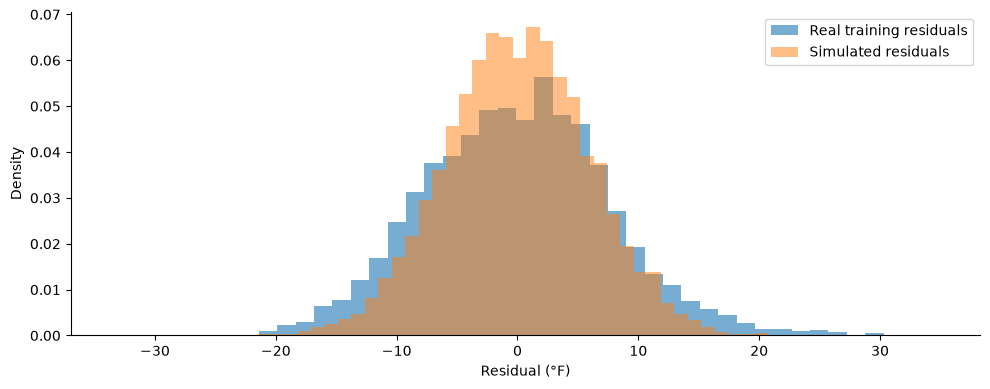

In [7]:
beta = np.array([8., .6, .2, 3., -4.])
X = train[features].to_numpy()
sim_y = beta[0] + X @ beta[1:] + rng.normal(0, 6, len(train))
sim_fit = LinearRegression().fit(X, sim_y)
display(pd.DataFrame({'parameter': ['intercept']+features, 'generating': beta,
    'recovered': [sim_fit.intercept_, *sim_fit.coef_]}).round(3))
plt.hist(train.tmin_f-model.predict(train[features]), bins=45, density=True, alpha=.6, label='Real training residuals')
plt.hist(sim_y-sim_fit.predict(X), bins=45, density=True, alpha=.5, label='Simulated residuals')
plt.xlabel('Residual (°F)'); plt.ylabel('Density'); plt.legend()
save('simulation_check.png')


## Layers and sensitivity
The cost ratio changes the action threshold, not the fitted temperature model. At a fixed probability, increasing the missed-freeze penalty can only increase (or preserve) the number of flags. These scenarios do not estimate what GMU ought to spend.


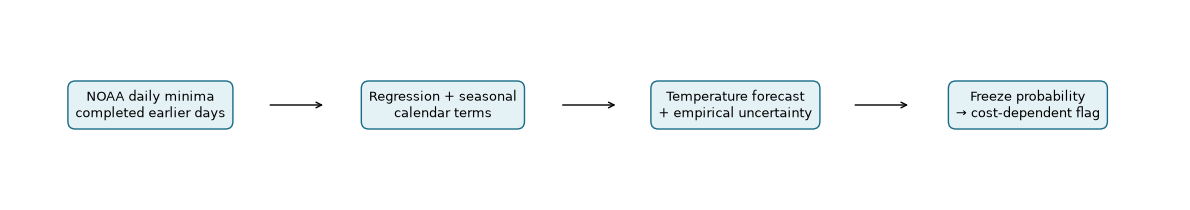

,freeze_probability,flag_if_r=2,flag_if_r=5,flag_if_r=10
0,0.05,False,False,False
1,0.10,False,False,True
2,0.20,False,True,True
3,0.40,True,True,True
4,0.70,True,True,True


In [8]:
fig, ax = plt.subplots(figsize=(12, 2.2))
ax.axis('off')
labels = ['NOAA daily minima\ncompleted earlier days', 'Regression + seasonal\ncalendar terms', 'Temperature forecast\n+ empirical uncertainty', 'Freeze probability\n→ cost-dependent flag']
for i, label in enumerate(labels):
    x = .12 + i*.25
    ax.text(x,.5,label,ha='center',va='center',fontsize=9,bbox={'boxstyle':'round,pad=.6','facecolor':'#e5f2f5','edgecolor':'#176b87'},transform=ax.transAxes)
    if i < 3:
        ax.annotate('',xy=(x+.15,.5),xytext=(x+.10,.5),xycoords='axes fraction',arrowprops={'arrowstyle':'->'})
save('layers.png')
display(pd.DataFrame({'freeze_probability': [.05,.1,.2,.4,.7], **{
    f'flag_if_r={r}': np.array([.05,.1,.2,.4,.7]) >= 1/(r+1) for r in [2,5,10]}}))


## Limits and next steps
This is a retrospective station-air proxy study, not a deployed campus ice predictor. It lacks pavement temperature, precipitation/wetness at decision time, actual treatment records, local cost estimates, and archived weather forecasts. Freeze occurrence is not synonymous with ice or injury. A daily minimum can occur outside the overnight treatment window. Lagged final records may be revised or delayed; real-time availability must be checked.

Regression assumes a stable linear association plus a smooth annual cycle. Calibration residuals may not transfer to cold fronts or extreme events; seasonal coverage and reliability tables reveal weaknesses, not proof of safety. There is no guarantee outside the observed temperature range, at other locations, or at longer horizons. Consecutive weather days are dependent; the observed test-score difference has not been given an independence-based significance claim.

Before the final presentation: team members choose a defensible loss scenario (or retain sensitivity reporting), audit forecast-time availability, obtain hourly/pavement or archived forecast data if feasible, and run rolling-origin checks without quietly tuning on this test set. The final target must match the overnight decision or be explicitly revised in the decision log. Do not claim measured dollar savings from assumed penalties.
